# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [1]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [5]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

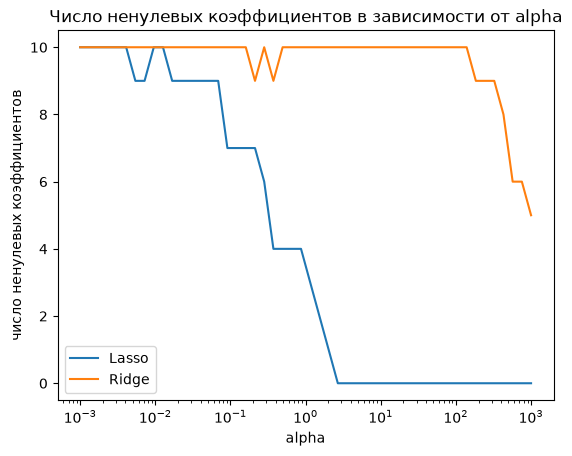

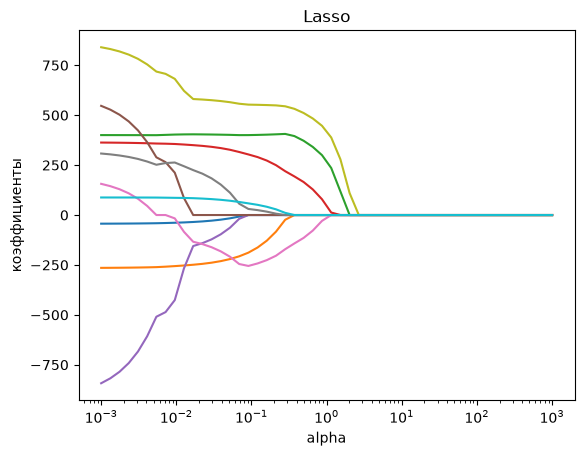

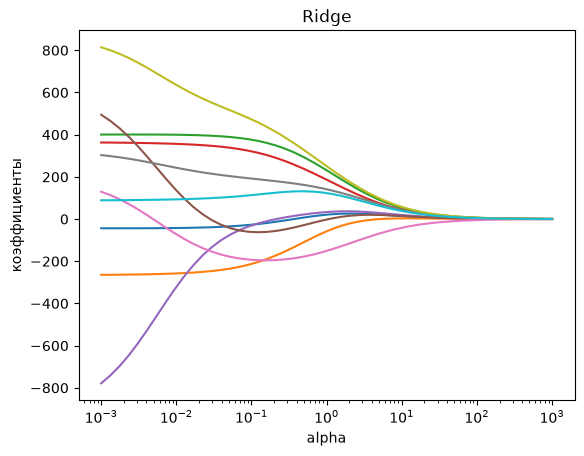

In [11]:
import matplotlib.pyplot as plt

alphas = np.logspace(-3, 3, 50)
eps = 0.5  

L1 = []
L2 = []

for a in alphas:
    L1.append(Lasso(alpha=a, max_iter=100000).fit(X_train, y_train).coef_)
    L2.append(Ridge(alpha=a).fit(X_train, y_train).coef_)

L1 = np.array(lasso_coefs)
L2 = np.array(ridge_coefs)


plt.plot(alphas, (abs(L1) >= eps).sum(axis=1), label="Lasso")
plt.plot(alphas, (abs(L2) >= eps).sum(axis=1), label="Ridge")
plt.title("Число ненулевых коэффициентов в зависимости от alpha")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("число ненулевых коэффициентов")
plt.legend()
plt.show()

plt.plot(alphas, L1)
plt.xscale("log")
plt.title("Lasso")
plt.xlabel("alpha")
plt.ylabel("коэффициенты")
plt.show()

plt.plot(alphas, L2)
plt.xscale("log")
plt.title("Ridge")
plt.xlabel("alpha")
plt.ylabel("коэффициенты")
plt.show()

Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [4]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model = Ridge().fit(X_train, y_train)
y_pred = model.predict(X_test)
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("MAE: ", round(mean_absolute_error(y_test, y_pred), 2))
print("R2:  ", round(r2_score(y_test, y_pred), 3))

RMSE: 58.3
MAE:  49.6
R2:   0.36


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

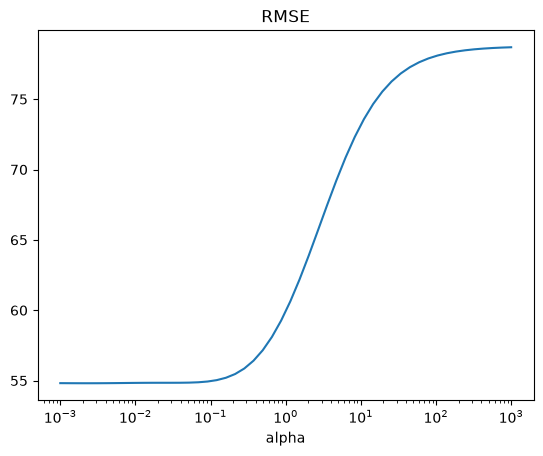

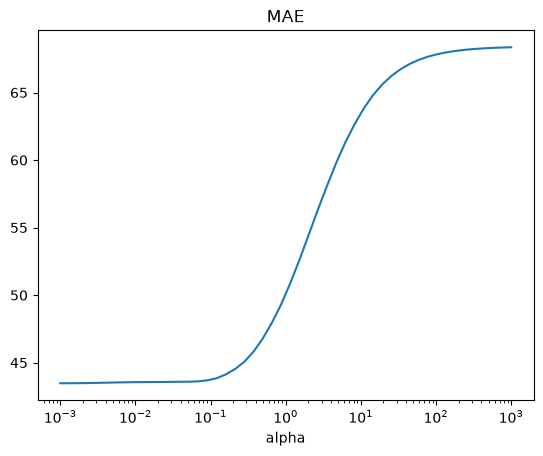

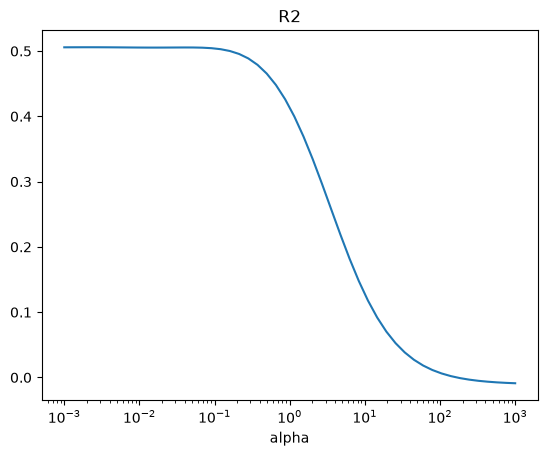

Лучший alpha по RMSE: 0.0023
RMSE: 55.81
MAE:  47.12
R2:   0.413

Лучший alpha по MAE: 0.0013
RMSE: 55.84
MAE:  47.14
R2:   0.413

Лучший alpha по R2: 1000.0
RMSE: 72.8
MAE:  59.93
R2:   0.002


In [26]:
import matplotlib.pyplot as plt

alphas = np.logspace(-3, 3, 50)

rmse = []
mae = []
r2_l = []

for a in alphas:
    model = Ridge(alpha=a)
    rmse2 = -cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean()
    mae2 = -cross_val_score(model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error").mean()
    r2 = cross_val_score(model, X_train, y_train, cv=5, scoring="r2").mean()

    rmse.append(rmse2)
    mae.append(mae2)
    r2_l.append(r2)

plt.plot(alphas, rmse)
plt.xscale("log")
plt.xlabel("alpha")
plt.title("RMSE")
plt.show()

plt.plot(alphas, mae)
plt.xscale("log")
plt.xlabel("alpha")
plt.title("MAE")

plt.show()

plt.plot(alphas, r2_l)
plt.xscale("log")
plt.xlabel("alpha")
plt.title("R2")
plt.show()

b_rmse = alphas[np.argmin(rmse)]
b_mae = alphas[np.argmin(mae)]
b_r2 = alphas[np.argmin(r2_l)]
print("Лучший alpha по RMSE:", round(b_rmse, 4))
print_metrics(y_test, Ridge(alpha=b_rmse).fit(X_train, y_train).predict(X_test))

print("\nЛучший alpha по MAE:", round(b_mae, 4))
print_metrics(y_test, Ridge(alpha=b_mae).fit(X_train, y_train).predict(X_test))

print("\nЛучший alpha по R2:", round(b_r2, 4))
print_metrics(y_test, Ridge(alpha=b_r2).fit(X_train, y_train).predict(X_test))

__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

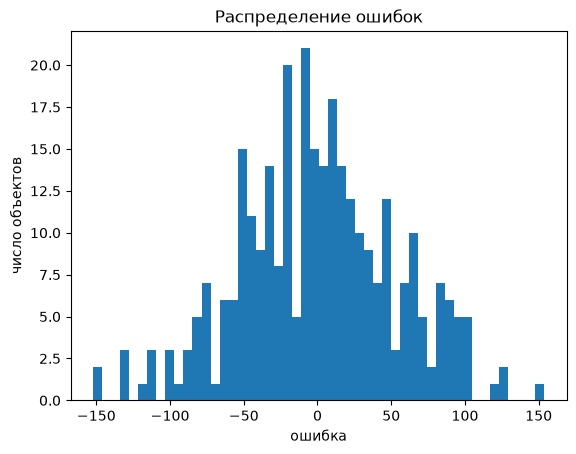

In [29]:
import matplotlib.pyplot as plt

model = Ridge(alpha=0.0023).fit(X_train, y_train)
predictions = model.predict(X_train)
errors = y_train - predictions

plt.hist(errors, bins=50)
plt.xlabel("ошибка")
plt.ylabel("число объектов")
plt.title("Распределение ошибок")
plt.show()

Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [30]:
from sklearn.metrics import mean_squared_error, r2_score

model = Ridge(alpha=0.0023).fit(X_train, y_train)
errors = y_train - model.predict(X_train)

good = abs(errors) < 2.5 * errors.std()
print("Удалено объектов:", (good == False).sum())

model2 = Ridge(alpha=0.002).fit(X_train[good], y_train[good])
pred1 = model.predict(X_test)
pred2 = model2.predict(X_test)

print("До удаления:    RMSE =", round(np.sqrt(mean_squared_error(y_test, pred1)), 2), " R2 =", round(r2_score(y_test, pred1), 3))
print("После удаления: RMSE =", round(np.sqrt(mean_squared_error(y_test, pred2)), 2), " R2 =", round(r2_score(y_test, pred2), 3))

Удалено объектов: 3
До удаления:    RMSE = 55.82  R2 = 0.413
После удаления: RMSE = 55.96  R2 = 0.41


__Задание 3.__ Отчёт

**(2 балла)**

In [ ]:
# code here